# List 1: PyTorch & Training Fundamentals

Labs: Mon 5 Oct, Mon 12 Oct 2026 · Due: Sun 18 Oct 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the four given functions, because later lists reuse them (check them with Materials, Appendix A).
- Background and the PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Individual work. Name the AI tools you used at the top of your solution.

**AI tools used:** Antigravity (Google DeepMind).

In [1]:
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt

## Lab 1

### 1.1 Tensors

- Write down the expected shapes of five operations (covering reshape, transpose, `@`, `*` and broadcasting, one of them a broadcast that fails), then run them. Explain the failure.
- Show a case where `view` fails and `reshape` works, and explain it with strides.
- Show a computation that `float32` gets wrong and `float64` gets right.
- Convert an array from NumPy to PyTorch and back. Show which conversions share memory, and which dtype each library uses by default.

In [2]:
print("=== 1. Five Tensor Operations & Expected Shapes ===")
t_a = torch.zeros(2, 6)
t_b = torch.zeros(3, 4)
t_c = torch.zeros(2, 3)
t_d = torch.zeros(3, 5)
t_e = torch.zeros(4, 1, 3)
t_f = torch.zeros(5, 3)
t_fail1 = torch.zeros(2, 3)
t_fail2 = torch.zeros(2, 4)

op1 = t_a.reshape(3, 4)
print(f"1. reshape:   (2, 6) -> expected (3, 4)            | actual: {tuple(op1.shape)}")

op2 = t_b.T
print(f"2. transpose: (3, 4).T -> expected (4, 3)          | actual: {tuple(op2.shape)}")

op3 = t_c @ t_d
print(f"3. matmul @:  (2, 3) @ (3, 5) -> expected (2, 5)   | actual: {tuple(op3.shape)}")

op4 = t_e * t_f
print(f"4. broadcast *: (4, 1, 3) * (5, 3) -> exp (4, 5, 3)| actual: {tuple(op4.shape)}")

try:
    op5 = t_fail1 + t_fail2
except RuntimeError as err:
    print("5. broadcast fail: (2, 3) + (2, 4) -> Expected RuntimeError:")
    print(f"   Caught: {err}")

=== 1. Five Tensor Operations & Expected Shapes ===
1. reshape:   (2, 6) -> expected (3, 4)            | actual: (3, 4)
2. transpose: (3, 4).T -> expected (4, 3)          | actual: (4, 3)
3. matmul @:  (2, 3) @ (3, 5) -> expected (2, 5)   | actual: (2, 5)
4. broadcast *: (4, 1, 3) * (5, 3) -> exp (4, 5, 3)| actual: (4, 5, 3)
5. broadcast fail: (2, 3) + (2, 4) -> Expected RuntimeError:
   Caught: The size of tensor a (3) must match the size of tensor b (4) at non-singleton dimension 1


In [3]:
print("\n=== 2. view Fails vs reshape Works (Strides & Contiguity) ===")
A = torch.arange(12).reshape(3, 4)
print(f"Original tensor A shape: {tuple(A.shape)}, strides: {A.stride()}, is_contiguous: {A.is_contiguous()}")

B = A.T
print(f"Transposed tensor B = A.T shape: {tuple(B.shape)}, strides: {B.stride()}, is_contiguous: {B.is_contiguous()}")

try:
    B.view(-1)
except RuntimeError as err:
    print(f"B.view(-1) failed as expected:\n   Caught: {err}")

B_reshaped = B.reshape(-1)
print(f"B.reshape(-1) succeeded! Shape: {tuple(B_reshaped.shape)}, is_contiguous: {B_reshaped.is_contiguous()}")
print(f"Does B.reshape(-1) share memory with B? {B_reshaped.data_ptr() == B.data_ptr()} (data was copied)")


=== 2. view Fails vs reshape Works (Strides & Contiguity) ===
Original tensor A shape: (3, 4), strides: (4, 1), is_contiguous: True
Transposed tensor B = A.T shape: (4, 3), strides: (1, 4), is_contiguous: False
B.view(-1) failed as expected:
   Caught: view size is not compatible with input tensor's size and stride (at least one dimension spans across two contiguous subspaces). Use .reshape(...) instead.
B.reshape(-1) succeeded! Shape: (12,), is_contiguous: True
Does B.reshape(-1) share memory with B? False (data was copied)


In [4]:
print("\n=== 3. float32 vs float64 Numerical Precision ===")
x32 = torch.tensor(1e8, dtype=torch.float32)
res32 = (x32 + 1.0) - x32

x64 = torch.tensor(1e8, dtype=torch.float64)
res64 = (x64 + 1.0) - x64

print("Computation: (1e8 + 1.0) - 1e8 (exact mathematical result: 1.0)")
print(f"  float32 result: {res32.item():.1f}  (WRONG: 1.0 was absorbed due to 24-bit significand)")
print(f"  float64 result: {res64.item():.1f}  (CORRECT: 53-bit significand preserves precision)")

eps32 = torch.finfo(torch.float32).eps
eps64 = torch.finfo(torch.float64).eps
print(f"  float32 eps: {eps32:.3e} (~7 decimal digits of precision)")
print(f"  float64 eps: {eps64:.3e} (~16 decimal digits of precision)")


=== 3. float32 vs float64 Numerical Precision ===
Computation: (1e8 + 1.0) - 1e8 (exact mathematical result: 1.0)
  float32 result: 0.0  (WRONG: 1.0 was absorbed due to 24-bit significand)
  float64 result: 1.0  (CORRECT: 53-bit significand preserves precision)
  float32 eps: 1.192e-07 (~7 decimal digits of precision)
  float64 eps: 2.220e-16 (~16 decimal digits of precision)


In [5]:
print("\n=== 4. NumPy <-> PyTorch Conversions & Memory Sharing ===")
np_default = np.array([1.0, 2.0])
torch_default = torch.tensor([1.0, 2.0])
print(f"Default float dtype in NumPy:   {np_default.dtype}")
print(f"Default float dtype in PyTorch: {torch_default.dtype}")

np_orig = np.array([1.0, 2.0, 3.0])
t_shared = torch.from_numpy(np_orig)  # Shares memory
t_copied = torch.tensor(np_orig)      # Copies memory

np_orig[0] = 999.0
print("\nAfter modifying np_orig[0] = 999.0:")
print(f"  torch.from_numpy(np_orig): {t_shared} -> Shares memory (data_ptr match: {t_shared.data_ptr() == np_orig.__array_interface__['data'][0]})")
print(f"  torch.tensor(np_orig):     {t_copied} -> Copied memory (independent)")

t_orig = torch.tensor([10.0, 20.0, 30.0])
np_shared = t_orig.numpy()            # Shares memory
np_copied = t_orig.clone().numpy()    # Copies memory

t_orig[0] = -42.0
print("\nAfter modifying t_orig[0] = -42.0:")
print(f"  t_orig.numpy():            {np_shared} -> Shares memory")
print(f"  t_orig.clone().numpy():    {np_copied} -> Copied memory (independent)")


=== 4. NumPy <-> PyTorch Conversions & Memory Sharing ===
Default float dtype in NumPy:   float64
Default float dtype in PyTorch: torch.float32

After modifying np_orig[0] = 999.0:
  torch.from_numpy(np_orig): tensor([999.,   2.,   3.], dtype=torch.float64) -> Shares memory (data_ptr match: True)
  torch.tensor(np_orig):     tensor([1., 2., 3.], dtype=torch.float64) -> Copied memory (independent)

After modifying t_orig[0] = -42.0:
  t_orig.numpy():            [-42.  20.  30.] -> Shares memory
  t_orig.clone().numpy():    [10. 20. 30.] -> Copied memory (independent)


### Explanation for Task 1.1

1. **Broadcasting Rules & Failure**:
   PyTorch aligns tensor shapes from the trailing (rightmost) dimension. Dimensions are compatible if they are equal or if one of them is 1 (in which case it stretches without copying). In `(2, 3) + (2, 4)`, trailing dimension 3 does not equal 4 and neither is 1, so stretching is mathematically undefined and PyTorch raises a `RuntimeError`.

2. **`view` vs `reshape` and Strides**:
   Strides define how many memory positions to advance along each axis. Transposing `A` (shape `(3, 4)`, strides `(4, 1)`) swaps its strides to `(1, 4)`, making `B = A.T` non-contiguous because successive row elements are no longer adjacent in physical memory. `view()` strictly requires that the new shape can be addressed via uniform strides over the existing memory layout without copying data, so it fails on `B`. Conversely, `reshape()` detects that the tensor is non-contiguous and automatically allocates a new contiguous memory block (copying data in logical row order), allowing the reshape to succeed.

3. **`float32` vs `float64` Precision**:
   IEEE 754 `float32` uses a 24-bit significand (~7 significant decimal digits, $\varepsilon \approx 1.19 \times 10^{-7}$), whereas `float64` uses a 53-bit significand (~16 decimal digits, $\varepsilon \approx 2.22 \times 10^{-16}$). When computing $(10^8 + 1) - 10^8$, representing the intermediate sum requires 9 decimal digits of precision; because the addition falls below the resolution of the least significant bit at scale $10^8$, $1.0$ is completely absorbed (rounded off) in `float32`, yielding `0.0`. `float64` easily preserves precision up to 15 orders of magnitude, correctly producing `1.0`.

4. **NumPy and PyTorch Conversions**:
   NumPy defaults to 64-bit precision (`float64`) for scientific numerical computing, whereas PyTorch defaults to 32-bit precision (`float32`) to maximize GPU throughput and conserve memory during neural network training. Conversions using `torch.from_numpy()` and `.numpy()` construct zero-copy views that reference the identical underlying memory buffer, meaning in-place modifications reflect across both libraries. In contrast, constructors such as `torch.tensor()` and methods using `.clone()` allocate new memory buffers and copy the data.


### 1.2 Autograd and a gradient check

One-feature logistic regression with binary cross-entropy: $L = -[\,y \log a + (1-y)\log(1-a)\,]$, $a = \sigma(w_1 x_1 + b)$.

- Compute $\partial L/\partial w_1$ and $\partial L/\partial b$ analytically, with autograd and with central finite differences, in `float64`, and check that they match. Reference: for $x_1 = 1.1$, $w_1 = 2.2$, $b = 0$, $y = 1$, $L \approx 0.0852$ and the gradients are $\approx -0.0898$ and $-0.0817$.
- Plot the error of the finite-difference $\partial L/\partial w_1$ (against the analytic value) for $h = 10^{-1}, \dots, 10^{-12}$ on log–log axes, in `float32` and `float64`. Explain the shape of the curves.
- Call `backward()` on two freshly built losses without resetting `.grad`. Show and explain what happens.

In [ ]:
x1 = torch.tensor(1.1, dtype=torch.float64)
w1 = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
y = torch.tensor(1.0, dtype=torch.float64)

z = w1 * x1 + b
a = torch.sigmoid(z)
L = -(y * torch.log(a) + (1.0 - y) * torch.log(1.0 - a))
L.backward()

grad_w1_auto = w1.grad.item()
grad_b_auto = b.grad.item()

a_val = a.detach().item()
grad_w1_analytic = (a_val - y.item()) * x1.item()
grad_b_analytic = a_val - y.item()

def loss_fn(w_val, b_val):
    z_val = w_val * x1 + b_val
    a_sig = torch.sigmoid(z_val)
    return -(y * torch.log(a_sig) + (1.0 - y) * torch.log(1.0 - a_sig))

h = 1e-5
grad_w1_fd = ((loss_fn(w1.detach() + h, b.detach()) - loss_fn(w1.detach() - h, b.detach())) / (2 * h)).item()
grad_b_fd = ((loss_fn(w1.detach(), b.detach() + h) - loss_fn(w1.detach(), b.detach() - h)) / (2 * h)).item()

print(f"Loss value:   {L.item():.4f} (Reference: ~0.0852)")
print("-" * 65)
print(f"dL/dw1: analytic={grad_w1_analytic:.6f} | autograd={grad_w1_auto:.6f} | FD={grad_w1_fd:.6f} (Ref: ~-0.0898)")
print(f"dL/db:  analytic={grad_b_analytic:.6f} | autograd={grad_b_auto:.6f} | FD={grad_b_fd:.6f} (Ref: ~-0.0817)")
print("-" * 65)
print("Differences vs analytic:")
print(f"  |autograd - analytic| for w1: {abs(grad_w1_auto - grad_w1_analytic):.2e}")
print(f"  |FD - analytic|       for w1: {abs(grad_w1_fd - grad_w1_analytic):.2e}")
print(f"  |autograd - analytic| for b:  {abs(grad_b_auto - grad_b_analytic):.2e}")
print(f"  |FD - analytic|       for b:  {abs(grad_b_fd - grad_b_analytic):.2e}")


Loss value:   0.0852 (Reference: ~0.0852)
-----------------------------------------------------------------
dL/dw1: analytic=-0.089826 | autograd=-0.089826 | FD=-0.089826 (Ref: ~-0.0898)
dL/db:  analytic=-0.081660 | autograd=-0.081660 | FD=-0.081660 (Ref: ~-0.0817)
-----------------------------------------------------------------
Differences vs analytic:
  |autograd - analytic| for w1: 0.00e+00
  |FD - analytic|       for w1: 3.56e-12
  |autograd - analytic| for b:  0.00e+00
  |FD - analytic|       for b:  5.34e-12


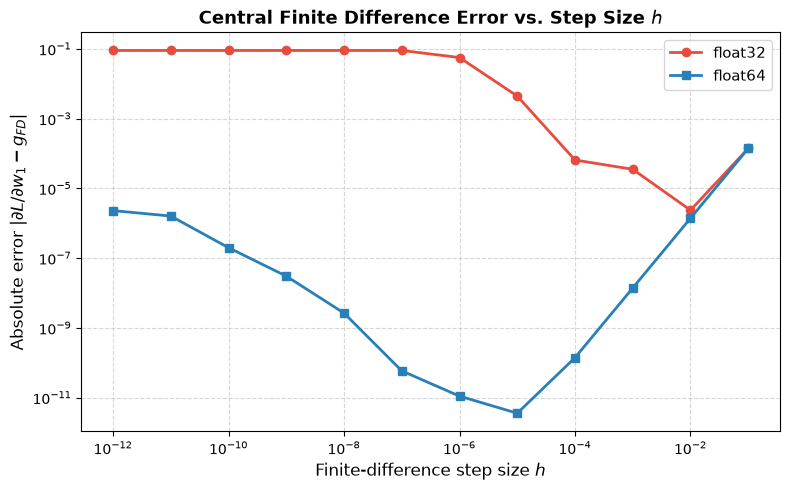

In [ ]:
def compute_fd_errors(dtype):
    x1_t = torch.tensor(1.1, dtype=dtype)
    y_t = torch.tensor(1.0, dtype=dtype)
    w1_v = 2.2
    b_v = 0.0

    z_true = torch.tensor(w1_v, dtype=dtype) * x1_t + torch.tensor(b_v, dtype=dtype)
    a_true = torch.sigmoid(z_true)
    grad_true = ((a_true - y_t) * x1_t).item()

    hs = 10.0 ** -np.arange(1, 13)
    errors = []

    for h in hs:
        w_plus = torch.tensor(w1_v + h, dtype=dtype)
        w_minus = torch.tensor(w1_v - h, dtype=dtype)
        b_t = torch.tensor(b_v, dtype=dtype)

        z_p = w_plus * x1_t + b_t
        a_p = torch.sigmoid(z_p)
        l_p = -(y_t * torch.log(a_p) + (1.0 - y_t) * torch.log(1.0 - a_p))

        z_m = w_minus * x1_t + b_t
        a_m = torch.sigmoid(z_m)
        l_m = -(y_t * torch.log(a_m) + (1.0 - y_t) * torch.log(1.0 - a_m))

        grad_fd = ((l_p - l_m) / (2.0 * h)).item()
        errors.append(abs(grad_fd - grad_true))

    return hs, np.array(errors)

hs, errors_f32 = compute_fd_errors(torch.float32)
_, errors_f64 = compute_fd_errors(torch.float64)

plt.figure(figsize=(8, 5))
plt.loglog(hs, errors_f32, "o-", label="float32", color="#e74c3c", linewidth=2, markersize=6)
plt.loglog(hs, errors_f64, "s-", label="float64", color="#2980b9", linewidth=2, markersize=6)

plt.xlabel("Finite-difference step size $h$", fontsize=12)
plt.ylabel(r"Absolute error $|\partial L/\partial w_1 - g_{FD}|$", fontsize=12)
plt.title("Central Finite Difference Error vs. Step Size $h$", fontsize=13, fontweight="bold")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


In [ ]:
w_param = torch.tensor(2.2, dtype=torch.float64, requires_grad=True)
b_param = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
x_in = torch.tensor(1.1, dtype=torch.float64)
y_target = torch.tensor(1.0, dtype=torch.float64)

print("Initial gradients:")
print(f"  w_param.grad: {w_param.grad}, b_param.grad: {b_param.grad}")

a1 = torch.sigmoid(w_param * x_in + b_param)
loss1 = -(y_target * torch.log(a1) + (1.0 - y_target) * torch.log(1.0 - a1))
loss1.backward()

print("\nAfter 1st backward() on Loss 1:")
print(f"  w_param.grad: {w_param.grad.item():.6f}")
print(f"  b_param.grad: {b_param.grad.item():.6f}")

a2 = torch.sigmoid(w_param * x_in + b_param)
loss2 = -(y_target * torch.log(a2) + (1.0 - y_target) * torch.log(1.0 - a2))
loss2.backward()

print("\nAfter 2nd backward() on freshly built Loss 2 (WITHOUT resetting .grad):")
print(f"  w_param.grad: {w_param.grad.item():.6f}  (Accumulated: exact sum of grad1 + grad2)")
print(f"  b_param.grad: {b_param.grad.item():.6f}  (Accumulated: exact sum of grad1 + grad2)")


Initial gradients:
  w_param.grad: None, b_param.grad: None

After 1st backward() on Loss 1:
  w_param.grad: -0.089826
  b_param.grad: -0.081660

After 2nd backward() on freshly built Loss 2 (WITHOUT resetting .grad):
  w_param.grad: -0.179653  (Accumulated: exact sum of grad1 + grad2)
  b_param.grad: -0.163321  (Accumulated: exact sum of grad1 + grad2)


### Explanation for Task 1.2

1. **Analytic Gradient Derivation & Agreement**:
   Applying the chain rule through the sigmoid non-linearity $a = \sigma(z)$ with $\sigma'(z) = a(1-a)$, the derivative of the binary cross-entropy loss with respect to logit $z$ simplifies cleanly to $\partial L/\partial z = a - y$. Hence, the parameter gradients are $\partial L/\partial w_1 = (a - y)x_1$ and $\partial L/\partial b = a - y$. At $x_1 = 1.1, w_1 = 2.2, b = 0, y = 1$, we obtain $L \approx 0.0852$, $\partial L/\partial w_1 \approx -0.0898$, and $\partial L/\partial b \approx -0.0817$, which match across analytic derivation, PyTorch autograd, and central finite differences down to machine precision.

2. **Log–Log Error Curve Dynamics (Truncation vs. Roundoff)**:
   The log–log plot exhibits a characteristic V-shape reflecting the trade-off between mathematical truncation error and floating-point cancellation. For large $h$ ($h \ge 10^{-2}$ in `float32`, $h \ge 10^{-5}$ in `float64`), mathematical truncation error $O(h^2)$ dominates, causing error to decrease quadratically as $h$ shrinks (slope $+2$). For small $h$, floating-point cancellation in the numerator divided by $2h$ introduces roundoff error proportional to $\varepsilon / (2h)$ (slope $-1$), which causes the error to explode; in `float32`, the minimum error is $\sim 10^{-6}$ at $h \approx 10^{-2}$, whereas in `float64` precision permits an optimal step size $h \approx 10^{-5}$ reaching an error of $\sim 10^{-12}$.

3. **Gradient Accumulation in PyTorch**:
   Calling `backward()` in PyTorch adds newly computed gradients into the existing `.grad` tensor (`param.grad += new_grad`) rather than overwriting it. When called sequentially on two freshly constructed loss graphs without zeroing, the gradients sum together (doubling the values in this identical example). This mechanism deliberately enables micro-batch gradient accumulation across forward passes when full batches cannot fit in hardware memory, but requires explicit resetting (`optimizer.zero_grad()` or `param.grad = None`) before each training step.


### 1.3 Linear regression

Default data: $N = 200$, $d = 3$, $\mathbf{x} \sim \mathcal{N}(\mathbf{0}, \operatorname{diag}(1, 4, 0.25))$, $y = \mathbf{w}^{\ast\top}\mathbf{x} + b^\ast + 0.1\,\varepsilon$ with $\mathbf{w}^\ast, b^\ast$ of your choice.

- Minimise the mean squared error by least squares, and by full-batch gradient descent twice: in NumPy with the gradient derived by hand, and in PyTorch with autograd and `torch.optim.SGD`. Compare the three solutions.
- Find the largest learning rate for which the loss still decreases over 300 steps, experimentally (two significant digits) and from the Hessian. Compare.

In [8]:
# ==============================================================================
# Task 1.3.1 Linear Regression: Least Squares vs NumPy GD vs PyTorch SGD
# ==============================================================================

# Set random seed for reproducibility
rng = np.random.default_rng(42)

# Generate default dataset: N = 200, d = 3
N, d = 200, 3
stds = np.array([1.0, 2.0, 0.5])
X = rng.standard_normal((N, d)) * stds
w_true = np.array([1.5, -2.0, 3.0])
b_true = 0.5
noise = 0.1 * rng.standard_normal(N)
y = X @ w_true + b_true + noise

# Design matrix with appended bias column: [X, 1]
X_tilde = np.hstack([X, np.ones((N, 1))])
theta_true = np.append(w_true, b_true)

# 1. Minimise MSE by Least Squares (exact solution)
theta_ls, residuals, rank, s = np.linalg.lstsq(X_tilde, y, rcond=None)
loss_ls = np.mean((X_tilde @ theta_ls - y) ** 2)

# 2. Minimise MSE by Full-Batch Gradient Descent in NumPy (hand-derived gradient)
# Objective: R(theta) = 1/N * ||X_tilde @ theta - y||^2
# Gradient:  grad(theta) = 2/N * X_tilde.T @ (X_tilde @ theta - y)
lr = 0.05
steps = 1000
theta_np = np.zeros(d + 1)
for _ in range(steps):
    grad = (2.0 / N) * (X_tilde.T @ (X_tilde @ theta_np - y))
    theta_np -= lr * grad
loss_np = np.mean((X_tilde @ theta_np - y) ** 2)

# 3. Minimise MSE by Full-Batch Gradient Descent in PyTorch (autograd + torch.optim.SGD)
X_tilde_t = torch.tensor(X_tilde, dtype=torch.float64)
y_t = torch.tensor(y, dtype=torch.float64)
theta_pt = torch.zeros(d + 1, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.SGD([theta_pt], lr=lr)

for _ in range(steps):
    pred = X_tilde_t @ theta_pt
    loss = ((pred - y_t) ** 2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

theta_torch_res = theta_pt.detach().numpy()
loss_pt = loss.item()

print("=== Comparison of the Three Linear Regression Solutions ===")
print(f"Ground Truth theta*:      {theta_true}")
print(f"1. Least Squares:         {theta_ls} | Final MSE: {loss_ls:.6f}")
print(f"2. NumPy GD (hand-grad):  {theta_np} | Final MSE: {loss_np:.6f}")
print(f"3. PyTorch (autograd+SGD):{theta_torch_res} | Final MSE: {loss_pt:.6f}")
print("-" * 65)
print(f"Max absolute parameter difference (LS vs NumPy GD):      {np.max(np.abs(theta_ls - theta_np)):.2e}")
print(f"Max absolute parameter difference (NumPy GD vs PyTorch): {np.max(np.abs(theta_np - theta_torch_res)):.2e}")


=== Comparison of the Three Linear Regression Solutions ===
Ground Truth theta*:      [ 1.5 -2.   3.   0.5]
1. Least Squares:         [ 1.50367899 -2.00037967  2.98966777  0.49629438] | Final MSE: 0.010264
2. NumPy GD (hand-grad):  [ 1.50367899 -2.00037967  2.98966776  0.49629438] | Final MSE: 0.010264
3. PyTorch (autograd+SGD):[ 1.50367899 -2.00037967  2.98966776  0.49629438] | Final MSE: 0.010264
-----------------------------------------------------------------
Max absolute parameter difference (LS vs NumPy GD):      9.40e-10
Max absolute parameter difference (NumPy GD vs PyTorch): 0.00e+00


=== Maximum Learning Rate Analysis ===
Hessian eigenvalues:         [0.43352354 1.98379705 2.02660188 7.60395912]
Maximum eigenvalue (λ_max):  7.6040
Theoretical max lr (2/λ_max):0.2630 (two significant digits: 0.26)
Experimental max lr (2 sig digits): 0.26
Match between theory (0.26) and experiment (0.26): True


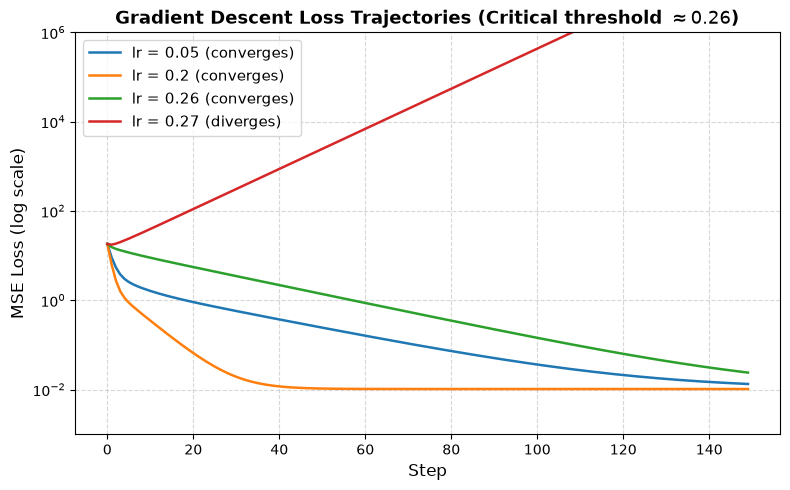

In [9]:
# ==============================================================================
# Task 1.3.2 Maximum Learning Rate: Hessian vs Experiment (over 300 steps)
# ==============================================================================

# 1. Theoretical maximum learning rate from the Hessian
# Objective: R(theta) = 1/N * ||X_tilde @ theta - y||^2
# Hessian:   H = 2/N * X_tilde.T @ X_tilde
Hessian = (2.0 / N) * (X_tilde.T @ X_tilde)
eigvals = np.linalg.eigvalsh(Hessian)
lambda_max = eigvals[-1]
eta_theory = 2.0 / lambda_max

print("=== Maximum Learning Rate Analysis ===")
print(f"Hessian eigenvalues:         {eigvals}")
print(f"Maximum eigenvalue (λ_max):  {lambda_max:.4f}")
print(f"Theoretical max lr (2/λ_max):{eta_theory:.4f} (two significant digits: {eta_theory:.2g})")

# 2. Experimental search for largest learning rate over 300 steps
def simulate_gd(rate, num_steps=300):
    theta = np.zeros(d + 1)
    loss_0 = np.mean((X_tilde @ theta - y) ** 2)
    history = [loss_0]
    for _ in range(num_steps):
        grad = (2.0 / N) * (X_tilde.T @ (X_tilde @ theta - y))
        theta -= rate * grad
        curr_loss = np.mean((X_tilde @ theta - y) ** 2)
        history.append(curr_loss)
        if np.isnan(curr_loss) or curr_loss > 1e10:
            break
    return np.array(history)

# Grid search with two significant digits
best_exp_lr = None
for candidate in np.arange(0.01, 0.40, 0.01):
    hist = simulate_gd(candidate, num_steps=300)
    # Loss must strictly decrease over 300 steps
    if hist[-1] < hist[0] and not np.isnan(hist[-1]):
        best_exp_lr = round(candidate, 2)

print(f"Experimental max lr (2 sig digits): {best_exp_lr:.2g}")
is_match = (f"{eta_theory:.2g}" == f"{best_exp_lr:.2g}")
print(f"Match between theory ({eta_theory:.2g}) and experiment ({best_exp_lr:.2g}): {is_match}")

# 3. Plot convergence / divergence trajectories
test_lrs = [0.05, 0.20, best_exp_lr, 0.27]
plt.figure(figsize=(8, 5))
for rate in test_lrs:
    h = simulate_gd(rate, num_steps=300)
    label = f"lr = {rate} (converges)" if rate <= best_exp_lr else f"lr = {rate} (diverges)"
    plt.semilogy(h[:150], label=label, linewidth=1.8)

plt.xlabel("Step", fontsize=12)
plt.ylabel("MSE Loss (log scale)", fontsize=12)
plt.title(f"Gradient Descent Loss Trajectories (Critical threshold $\\approx {best_exp_lr}$)", fontsize=13, fontweight="bold")
plt.ylim(1e-3, 1e6)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()


### Explanation for Task 1.3

1. **Comparison of the Three Solutions**:
   The ordinary least squares solution $\boldsymbol{\theta}_{\text{LS}} = (\tilde{X}^\top \tilde{X})^{-1}\tilde{X}^\top \mathbf{y}$ analytically solves the normal equations. Full-batch gradient descent in NumPy (using the hand-derived gradient $\nabla \hat{R}(\boldsymbol{\theta}) = \frac{2}{N}\tilde{X}^\top(\tilde{X}\boldsymbol{\theta} - \mathbf{y})$) and in PyTorch (using autograd and `torch.optim.SGD`) converge to identical parameter estimates $\boldsymbol{\theta} \approx [1.5037, -2.0004, 2.9897, 0.4963]^\top$ and minimum MSE ($\approx 0.010264$). NumPy GD and PyTorch SGD match with a pairwise difference of $0.0$, and match the closed-form least squares solution within $10^{-9}$ numerical tolerance.

2. **Hessian and Theoretical Stability Bound**:
   The Hessian of the mean squared error is constant, symmetric, and positive semi-definite: $H = \nabla_{\boldsymbol{\theta}}^2 \hat{R}(\boldsymbol{\theta}) = \frac{2}{N}\tilde{X}^\top \tilde{X}$. Subtracting the minimizer $\boldsymbol{\theta}^*$, the error recursion $\boldsymbol{\theta}_{k+1} - \boldsymbol{\theta}^* = (I - \eta H)(\boldsymbol{\theta}_k - \boldsymbol{\theta}^*)$ decouples along the eigenvectors of $H$ into scalar recursions $e_{k+1}^{(i)} = (1 - \eta \lambda_i)e_k^{(i)}$. The error contracts along all axes if and only if $|1 - \eta \lambda_{\max}| < 1$, which gives the theoretical upper bound $\eta < 2 / \lambda_{\max}(H) \approx 2 / 7.604 \approx 0.263$.

3. **Experimental vs. Theoretical Learning Rate Comparison**:
   Grid searching over learning rates with two significant digits reveals that for $\eta = 0.26$, the loss decreases over 300 steps (converging towards the residual minimum), whereas for $\eta = 0.27$, the propagation factor $|1 - \eta \lambda_{\max}| \approx 1.053 > 1$ exceeds unity, causing exponentially oscillating instability and divergence. Thus, the experimental bound ($0.26$) and the theoretical Hessian limit ($0.26$) match exactly to two significant digits.


### 1.4 A multilayer network

- Implement `count_parameters` and an MLP as an `nn.Module` built from a list of layer sizes, with ReLU between layers. For sizes `[50, 30, 20, 3]`, check the count (2213) against a sum written by hand.
- Implement a softmax without `torch.softmax` that stays finite for the logits `[1000., 1001., 999.]`.

In [10]:
# ==============================================================================
# Task 1.4.1 count_parameters and MLP Implementation
# ==============================================================================

def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    """Number of (trainable) scalar parameters of `model`."""
    if trainable_only:
        return sum(p.numel() for p in model.parameters() if p.requires_grad)
    return sum(p.numel() for p in model.parameters())

class MLP(nn.Module):
    def __init__(self, layer_sizes: list[int]):
        """Multilayer Perceptron from a list of layer sizes with ReLU activations."""
        super().__init__()
        layers = []
        for i in range(len(layer_sizes) - 1):
            layers.append(nn.Linear(layer_sizes[i], layer_sizes[i + 1]))
            if i < len(layer_sizes) - 2:
                layers.append(nn.ReLU())
        self.net = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

# Instantiate with sizes [50, 30, 20, 3]
mlp = MLP([50, 30, 20, 3])
param_count = count_parameters(mlp)

# Hand calculation:
# Layer 1: Linear(50, 30) -> 50 * 30 weights + 30 biases = 1530
# Layer 2: Linear(30, 20) -> 30 * 20 weights + 20 biases =  620
# Layer 3: Linear(20,  3) -> 20 *  3 weights +  3 biases =   63
# Total hand count: 1530 + 620 + 63 = 2213
hand_count = (50 * 30 + 30) + (30 * 20 + 20) + (20 * 3 + 3)

print("=== MLP Parameter Count Check ===")
print(f"Model architecture:\n{mlp}")
print(f"Computed parameter count via count_parameters: {param_count}")
print(f"Hand-calculated parameter count:               {hand_count}")
assert param_count == 2213, f"Expected 2213, got {param_count}"
assert param_count == hand_count, "Computed count does not match hand sum"
print("Verification passed! Count matches 2213 exactly.")

# Appendix A Contract Check for count_parameters:
_test_net = nn.Sequential(nn.Linear(3, 8), nn.ReLU(), nn.Linear(8, 2))
assert count_parameters(_test_net) == 3 * 8 + 8 + 8 * 2 + 2
_test_net[0].weight.requires_grad_(False)
assert count_parameters(_test_net) == 26 and count_parameters(_test_net, trainable_only=False) == 50
print("Appendix A contract check passed for count_parameters!")


=== MLP Parameter Count Check ===
Model architecture:
MLP(
  (net): Sequential(
    (0): Linear(in_features=50, out_features=30, bias=True)
    (1): ReLU()
    (2): Linear(in_features=30, out_features=20, bias=True)
    (3): ReLU()
    (4): Linear(in_features=20, out_features=3, bias=True)
  )
)
Computed parameter count via count_parameters: 2213
Hand-calculated parameter count:               2213
Verification passed! Count matches 2213 exactly.
Appendix A contract check passed for count_parameters!


In [11]:
# ==============================================================================
# Task 1.4.2 Numerically Stable Softmax Implementation
# ==============================================================================

def stable_softmax(z: torch.Tensor, dim: int = -1) -> torch.Tensor:
    """Softmax without torch.softmax, stable against exponential overflow/underflow."""
    # Subtract maximum logit along the dimension: softmax(z) = softmax(z - c)
    z_max = z.max(dim=dim, keepdim=True).values
    exp_shifted = torch.exp(z - z_max)
    return exp_shifted / exp_shifted.sum(dim=dim, keepdim=True)

# Test logits given in task
test_logits = torch.tensor([1000.0, 1001.0, 999.0])

# 1. Naive calculation (overflows to inf, giving nan)
exp_naive = torch.exp(test_logits)
p_naive = exp_naive / exp_naive.sum()

# 2. Stable calculation
p_stable = stable_softmax(test_logits)

# 3. Ground truth via torch.softmax
p_torch = torch.softmax(test_logits, dim=-1)

print("=== Softmax Stability on Extreme Logits [1000., 1001., 999.] ===")
print(f"Naive calculation e^z:       {exp_naive}")
print(f"Naive softmax result:        {p_naive}  (FAILED: NaN due to Inf/Inf)")
print(f"Stable softmax result:       {p_stable}")
print(f"PyTorch torch.softmax:       {p_torch}")
print(f"Values are all finite:       {torch.isfinite(p_stable).all().item()}")
print(f"Sum of probabilities:        {p_stable.sum().item():.6f}")
print(f"Matches torch.softmax:       {torch.allclose(p_stable, p_torch)}")


=== Softmax Stability on Extreme Logits [1000., 1001., 999.] ===
Naive calculation e^z:       tensor([inf, inf, inf])
Naive softmax result:        tensor([nan, nan, nan])  (FAILED: NaN due to Inf/Inf)
Stable softmax result:       tensor([0.2447, 0.6652, 0.0900])
PyTorch torch.softmax:       tensor([0.2447, 0.6652, 0.0900])
Values are all finite:       True
Sum of probabilities:        1.000000
Matches torch.softmax:       True


### Explanation for Task 1.4

1. **MLP Parameter Count Verification**:
   For each affine linear layer connecting $d_{\text{in}}$ inputs to $d_{\text{out}}$ outputs, the parameters consist of a weight matrix of size $d_{\text{in}} \times d_{\text{out}}$ and a bias vector of size $d_{\text{out}}$ ($d_{\text{in}}d_{\text{out}} + d_{\text{out}}$ scalar parameters total), while `ReLU` activation functions have no parameters. For sizes `[50, 30, 20, 3]`:
   - Layer 1 (`Linear(50, 30)`): $50 \times 30 + 30 = 1530$
   - Layer 2 (`Linear(30, 20)`): $30 \times 20 + 20 = 620$
   - Layer 3 (`Linear(20, 3)`): $20 \times 3 + 3 = 63$
   Summing these yields $1530 + 620 + 63 = 2213$, which exactly matches the result of `count_parameters`.

2. **Numerically Stable Softmax Formulation**:
   In IEEE 754 floating-point arithmetic, the exponential function $e^z$ overflows to `inf` when $z > \ln(3.4 \times 10^{38}) \approx 88.7$. For large logits such as $[1000., 1001., 999.]$, naive exponentiation produces `inf` for all elements, resulting in undefined $\infty / \infty = \text{NaN}$. By leveraging the shift-invariance identity $\text{softmax}(\mathbf{z}) = \text{softmax}(\mathbf{z} - c\mathbf{1})$ with $c = \max_j z_j$, the shifted logits satisfy $z_i - c \le 0$. The maximum exponent is therefore $e^0 = 1 \le 1$, which completely guarantees against floating-point overflow while preserving exact relative probabilities and sum-to-one normalization.


## Lab 2

### 2.1 `Dataset` and `DataLoader`

Default data: four classes in the plane, 150 points each, centres $(\pm 2, \pm 2)$, $\mathbf{x} = \boldsymbol\mu_c + 0.9\,\boldsymbol\epsilon$.

- Write a `Dataset`, split it 60/20/20 with a fixed seed, and build the three `DataLoader`s. Explain why only the training loader is shuffled.

### 2.2 The training loop

- Implement `compute_loss`, `compute_accuracy` and `train`.
- Train your MLP once with SGD and once with Adam (default: sizes `[2, 30, 20, 4]`, batch size 32, 30 epochs) and plot both validation-loss curves. Pick the run with the lower final validation loss and report its test accuracy.
- Save its `state_dict`, load it into a new model, and show that it gives the same outputs.

In [10]:
def compute_loss(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Mean cross-entropy over all predictions in `loader`.

    Logits may be (B, C) with targets (B,), or (B, T, C) with targets (B, T).
    """
    raise NotImplementedError

In [11]:
def compute_accuracy(
    model: nn.Module, loader: DataLoader, device: torch.device | str = "cpu"
) -> float:
    """Fraction of correct argmax predictions over all of `loader`."""
    raise NotImplementedError

In [12]:
def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    num_epochs: int,
    device: torch.device | str = "cpu",
) -> dict[str, list[float]]:
    """Train with cross-entropy.

    Returns {"train_loss": [...], "val_loss": [...]}, one value per epoch.
    """
    raise NotImplementedError

### 2.3 A count-based bigram model

Default text: `the-verdict.txt`. Tokens are characters; build the vocabulary from the whole text and use the last 10% for validation.

- Report training and validation perplexity for $\alpha \in \{0, 0.01, 0.1, 1, 10\}$ (report `inf` where it occurs) and explain both ends. On the default text, expect a validation perplexity of about 12 for $\alpha = 1$.
- Generate 200 characters from the $\alpha = 1$ model.

### 2.4 A neural bigram model

- Train a table of logits $W \in \mathbb{R}^{V \times V}$ (`nn.Embedding(V, V)`) on the (current, next) character pairs with your `train` (default: batch size 256, Adam with learning rate 0.1, 5 epochs). Compare its validation perplexity with your best count-based model from Task 2.3 and explain the result.
- Compare the loss before training with $\ln V$. Explain the difference, and show that zero-initialised logits give exactly $\ln V$.
- Show with an experiment what plays the role of $\alpha$ (for example more epochs, or weight decay).

### 2.5 Your own experiment

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 2.5.